In [16]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import load_img, img_to_array

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow:", tf.__version__)
print("GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow: 2.21.0
GPU available: False


In [17]:
base = None

search_locations = [
    "/root/.keras/datasets",
    "/content"
]

for location in search_locations:
    if not os.path.exists(location):
        continue

    for root, dirs, files_list in os.walk(location):
        if (
            os.path.isdir(os.path.join(root, "train", "cats"))
            and os.path.isdir(os.path.join(root, "train", "dogs"))
            and os.path.isdir(os.path.join(root, "validation", "cats"))
            and os.path.isdir(os.path.join(root, "validation", "dogs"))
        ):
            base = root
            break

    if base:
        break

if base is None:
    raise FileNotFoundError(
        "Dataset not found. Check that the dataset ZIP was extracted."
    )

train_dir = os.path.join(base, "train")
val_dir = os.path.join(base, "validation")

print("Dataset:", base)
print("Training directory exists:", os.path.isdir(train_dir))
print("Validation directory exists:", os.path.isdir(val_dir))

Dataset: /root/.keras/datasets/cats_and_dogs_extracted/cats_and_dogs_filtered
Training directory exists: True
Validation directory exists: True


In [18]:
IMG_SIZE = (128, 128)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    val_dir,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

class_names = train_ds.class_names

print("Class names:", class_names)
print("Class mapping:", {name: i for i, name in enumerate(class_names)})

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)

Found 2000 files belonging to 2 classes.
Found 1000 files belonging to 2 classes.
Class names: ['cats', 'dogs']
Class mapping: {'cats': 0, 'dogs': 1}


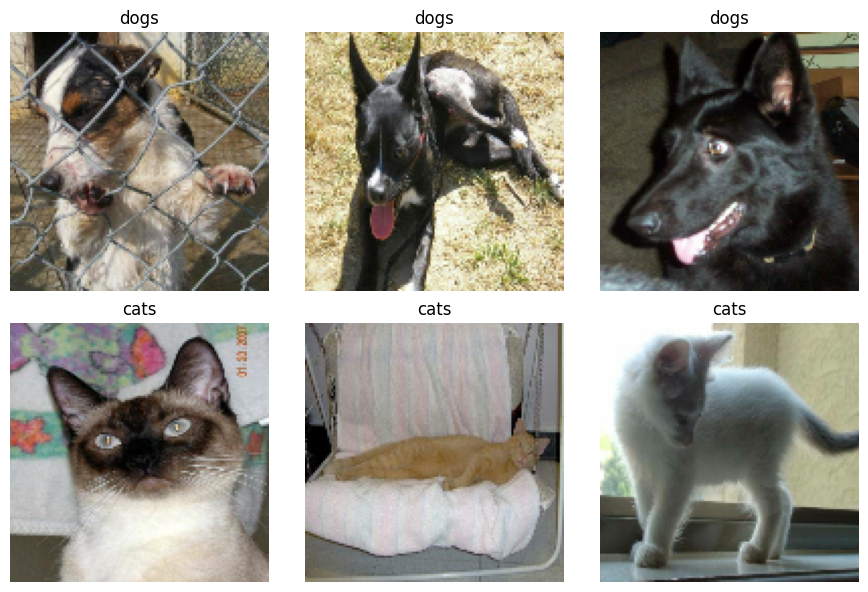

In [19]:
plt.figure(figsize=(9, 6))

for images, labels in train_ds.take(1):
    for i in range(6):
        plt.subplot(2, 3, i + 1)
        plt.imshow(tf.cast(images[i], tf.uint8).numpy())
        plt.title(class_names[int(labels[i].numpy()[0])])
        plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
model = models.Sequential([
    layers.Input(shape=(128, 128, 3)),

    layers.Rescaling(1.0 / 255),

    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),

    # Convolutional layer 1
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Convolutional layer 2
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    # Convolutional layer 3
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D(2, 2),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(1, activation="sigmoid")
])

model.summary()

print("Convolutional layers:",
      sum(isinstance(layer, layers.Conv2D) for layer in model.layers))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,889 (429.25 KB)

 Trainable params: 109,889 (429.25 KB)

 Non-trainable params: 0 (0.00 B)

Convolutional layers: 3


In [21]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Model compiled successfully!")

Model compiled successfully!


In [22]:
callbacks = [
    EarlyStopping(
        monitor="val_loss",
        patience=4,
        restore_best_weights=True
    ),
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2,
        min_lr=0.00001
    )
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 51s 784ms/step - accuracy: 0.4965 - loss: 0.6952 - val_accuracy: 0.5050 - val_loss: 0.6904 - learning_rate: 0.0010
Epoch 2/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 79s 734ms/step - accuracy: 0.5280 - loss: 0.6896 - val_accuracy: 0.5600 - val_loss: 0.6833 - learning_rate: 0.0010
Epoch 3/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 46s 734ms/step - accuracy: 0.5630 - loss: 0.6800 - val_accuracy: 0.5900 - val_loss: 0.6483 - learning_rate: 0.0010
Epoch 4/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 47s 740ms/step - accuracy: 0.5820 - loss: 0.6685 - val_accuracy: 0.6160 - val_loss: 0.6577 - learning_rate: 0.0010
Epoch 5/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 48s 761ms/step - accuracy: 0.5905 - loss: 0.6606 - val_accuracy: 0.5370 - val_loss: 0.7579 - learning_rate: 0.0010
Epoch 6/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 46s 728ms/step - accuracy: 0.6145 - loss: 0.6579 - val_accuracy: 0.5760 - val_loss: 0.6764 - learning_rate: 5.0000e-04
Epoch 7/15
63/63 ━━━━━━━━━━━━━━━━━━━━ 50s 794ms/step - accuracy: 0.6300 - loss

In [23]:
loss, accuracy = model.evaluate(val_ds, verbose=1)

print(f"Validation Loss: {loss:.4f}")
print(f"Validation Accuracy: {accuracy * 100:.2f}%")

32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 181ms/step - accuracy: 0.5900 - loss: 0.6483
Validation Loss: 0.6483
Validation Accuracy: 59.00%


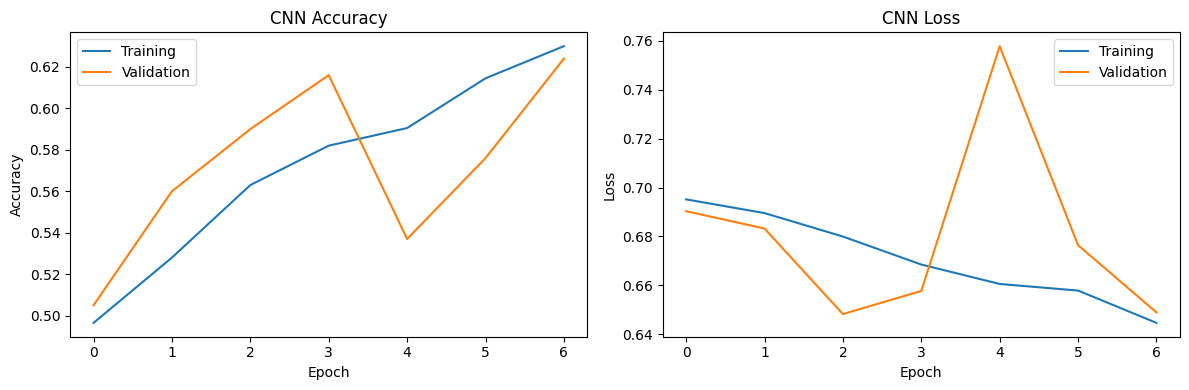

In [24]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.title("CNN Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.title("CNN Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

<Figure size 1200x1000 with 0 Axes>

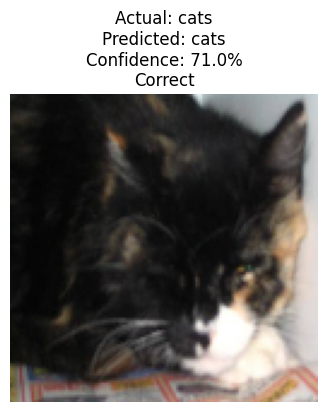

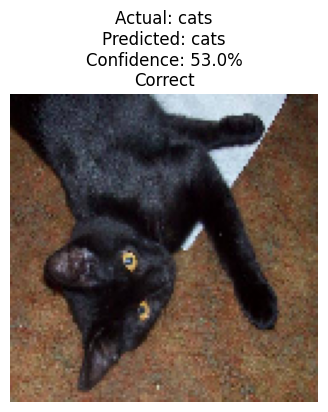

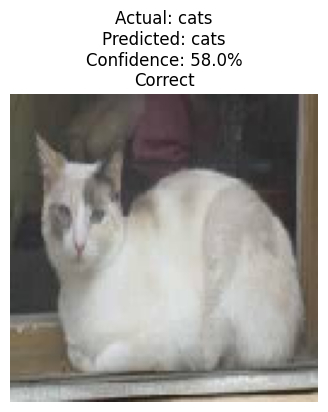

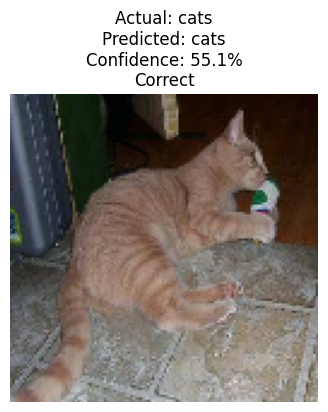

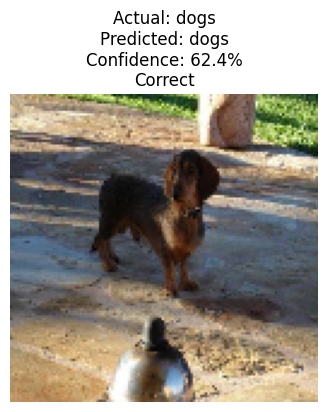

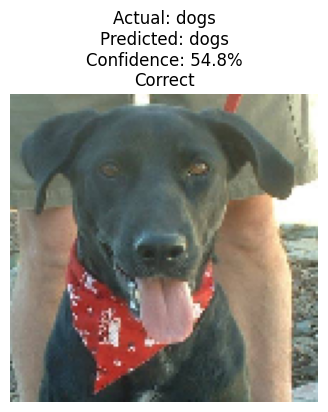

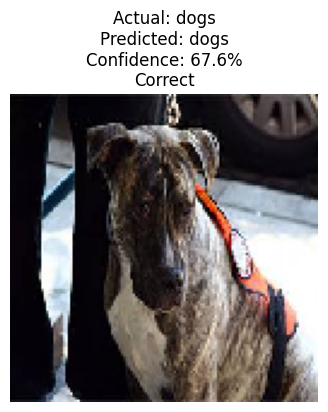

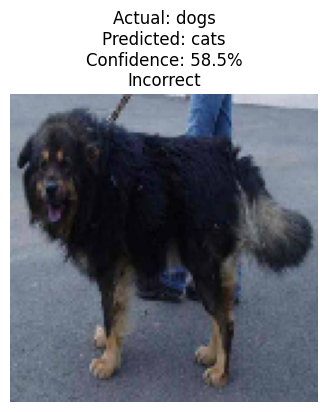


Prediction Results:
Actual Predicted  Confidence (%)  Correct
  cats      cats           71.04     True
  cats      cats           53.02     True
  cats      cats           58.05     True
  cats      cats           55.14     True
  dogs      dogs           62.45     True
  dogs      dogs           54.77     True
  dogs      dogs           67.64     True
  dogs      cats           58.52    False


In [25]:
plt.figure(figsize=(12, 10))
results = []

for animal in class_names:
    folder = os.path.join(val_dir, animal)
    image_files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    random.seed(SEED)
    selected = random.sample(image_files, min(4, len(image_files)))

    for filename in selected:
        path = os.path.join(folder, filename)

        img = load_img(path, target_size=IMG_SIZE)
        img_array = img_to_array(img)
        img_array = np.expand_dims(img_array, axis=0)

        probability = float(model.predict(img_array, verbose=0)[0][0])

        predicted_index = 1 if probability >= 0.5 else 0
        predicted = class_names[predicted_index]
        confidence = probability if predicted_index == 1 else 1 - probability

        actual = animal
        correct = actual == predicted

        results.append({
            "Actual": actual,
            "Predicted": predicted,
            "Confidence (%)": round(confidence * 100, 2),
            "Correct": correct
        })

        plt.figure(figsize=(4, 4))
        plt.imshow(img)
        plt.title(
            f"Actual: {actual}\n"
            f"Predicted: {predicted}\n"
            f"Confidence: {confidence * 100:.1f}%"
            f"\n{'Correct' if correct else 'Incorrect'}"
        )
        plt.axis("off")
        plt.show()

print("\nPrediction Results:")
print(pd.DataFrame(results).to_string(index=False))

In [26]:
results_df = pd.DataFrame(results)

correct = results_df["Correct"].sum()
total = len(results_df)

print("Correct predictions:", correct)
print("Total images:", total)
print("Selected-image accuracy:", round(correct / total * 100, 2), "%")

Correct predictions: 7
Total images: 8
Selected-image accuracy: 87.5 %


In [27]:
model.save("dog_cat_cnn.keras")

pd.DataFrame(history.history).to_csv(
    "training_results.csv",
    index_label="Epoch"
)

print("Model saved: dog_cat_cnn.keras")
print("Training results saved: training_results.csv")

Model saved: dog_cat_cnn.keras
Training results saved: training_results.csv


In [28]:
print("PROJECT: Dog-Cat Image Classification")
print("Model: Convolutional Neural Network")
print("Convolutional layers: 3")
print("Image size: 128 x 128")
print("Epochs completed:", len(history.history["accuracy"]))
print(f"Validation accuracy: {accuracy * 100:.2f}%")
print(f"Validation loss: {loss:.4f}")

PROJECT: Dog-Cat Image Classification
Model: Convolutional Neural Network
Convolutional layers: 3
Image size: 128 x 128
Epochs completed: 7
Validation accuracy: 59.00%
Validation loss: 0.6483
